# **Matrimonios 2023**

En este cuaderno se busca analizar los registros estadísticos de
matrimonios en el año 2023, información aportada por el INEC.

### **Importaciones necesarias para el proyecto**





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##**Sección 1 - Análisis Exploratorio de Datos**



Lo importamos y manejamos los "Sin información" del archivo como nulos.

In [2]:
df = pd.read_csv('EMA_2023.csv',sep=';',na_values="Sin información")

### **Información general del dataframe**

**Dimensiones**


*   56.546 filas = Registros
*   43 columnas = Variables



In [3]:
df.shape

(56546, 43)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56546 entries, 0 to 56545
Data columns (total 43 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   prov_insc   56546 non-null  str    
 1   cant_insc   56546 non-null  str    
 2   parr_insc   56546 non-null  str    
 3   anio_insc   56546 non-null  int64  
 4   mes_insc    56546 non-null  str    
 5   dia_insc    56546 non-null  int64  
 6   fecha_insc  56546 non-null  str    
 7   hijos_rec   53314 non-null  float64
 8   mcap_bie    51690 non-null  str    
 9   nac_1       56542 non-null  str    
 10  cod_pais1   56546 non-null  str    
 11  sexo_1      56546 non-null  str    
 12  anio_nac1   56545 non-null  float64
 13  mes_nac1    56545 non-null  str    
 14  dia_nac1    56545 non-null  float64
 15  fecha_nac1  56545 non-null  str    
 16  edad_1      56545 non-null  float64
 17  nmatant1    56433 non-null  float64
 18  est_civi1   56412 non-null  str    
 19  p_etnica1   55550 non-null  str    


###**Identificación y eliminación/llenado de nulos**

Primero analizamos la cantidad de nulos por porcentaje (si es que existen) en cada columna:

In [5]:
conteonulos = df.isnull().sum()
porcentajenulos = (conteonulos/len(df))*100
print(porcentajenulos[porcentajenulos>0].sort_values(ascending=False))

mcap_bie      8.587699
hijos_rec     5.715700
niv_inst2     4.276165
niv_inst1     3.796909
sabe_leer2    2.191136
sabe_leer1    2.023132
p_etnica2     1.911718
p_etnica1     1.761398
est_civi2     0.270576
est_civi1     0.236975
nmatant2      0.224596
nmatant1      0.199837
nac_1         0.007074
nac_2         0.005305
anio_nac2     0.003537
mes_nac2      0.003537
fecha_nac2    0.003537
dia_nac2      0.003537
anio_nac1     0.001768
fecha_nac1    0.001768
dia_nac1      0.001768
mes_nac1      0.001768
edad_1        0.001768
dtype: float64


In [6]:
print(conteonulos.sort_values(ascending=False))
conteonulos.sum()

mcap_bie      4856
hijos_rec     3232
niv_inst2     2418
niv_inst1     2147
sabe_leer2    1239
sabe_leer1    1144
p_etnica2     1081
p_etnica1      996
est_civi2      153
est_civi1      134
nmatant2       127
nmatant1       113
nac_1            4
nac_2            3
mes_nac2         2
anio_nac2        2
dia_nac2         2
fecha_nac2       2
anio_nac1        1
mes_nac1         1
edad_1           1
fecha_nac1       1
dia_nac1         1
anio_insc        0
prov_insc        0
cant_insc        0
parr_insc        0
cod_pais1        0
mes_insc         0
dia_insc         0
fecha_insc       0
sexo_1           0
parr_hab1        0
cant_hab1        0
prov_hab1        0
area_1           0
edad_2           0
sexo_2           0
cod_pais2        0
prov_hab2        0
cant_hab2        0
parr_hab2        0
area_2           0
dtype: int64


np.int64(17660)

Eliminaremos las filas donde dichas columnas con nulos tengan menos de 10 nulos en total. Esto porque estos pocos registros no afectarán a los resultados ya que contamos con más de 54.000 registros.

In [7]:
columnas_eliminar = conteonulos[(conteonulos>0) & (conteonulos<10)].index
df.dropna(subset=columnas_eliminar, inplace=True)

Ahora iremos columna por columna decidiendo cómo llenar los datos.

In [8]:
print(df['mcap_bie'].value_counts())
df['mcap_bie'] = df['mcap_bie'].fillna('No')

mcap_bie
No    51248
Si      436
Name: count, dtype: int64


In [9]:
print(df['hijos_rec'].value_counts().head())
df['hijos_rec'] = df['hijos_rec'].fillna(0).astype(int)

hijos_rec
0.0    32889
1.0    10933
2.0     6277
3.0     2147
4.0      631
Name: count, dtype: int64


En estas variables de acontinuación no podemos inferir nada sobre con qué datos rellenar o usar la moda para llenar los datos faltantes, así que solo los llenaremos con 'Sin información'

In [10]:
df['niv_inst1'] = df['niv_inst1'].fillna('Sin información')
df['niv_inst2'] = df['niv_inst2'].fillna('Sin información')
df['sabe_leer1'] = df['sabe_leer1'].fillna('Sin información')
df['sabe_leer2'] = df['sabe_leer2'].fillna('Sin información')
df['p_etnica1'] = df['p_etnica1'].fillna('Sin información')
df['p_etnica2'] = df['p_etnica2'].fillna('Sin información')

LLenaremos el número de matrimonios anteriores con 0. Al ser solo poco más de 100 nulos no nos afectará el poner un valor arbitrario, además de que la moda es por gran diferencia de 0. Con este resultado también inferimos que el estado civil anterior puede ser 'Soltero'

In [11]:
print(df['nmatant1'].value_counts().head())
print(df['nmatant2'].value_counts().head())
df['nmatant1'] = df['nmatant1'].fillna(0).astype(int)
df['nmatant2'] = df['nmatant2'].fillna(0).astype(int)
df['est_civi1'] = df['est_civi1'].fillna('Soltero')
df['est_civi2'] = df['est_civi2'].fillna('Soltero')

nmatant1
0.0    47890
1.0     8213
2.0      296
3.0       19
4.0        6
Name: count, dtype: int64
nmatant2
0.0    49845
1.0     6404
2.0      150
3.0       11
Name: count, dtype: int64


Una vez con todos estos cambios nuestro dataframe está listo para trabajarse sin problemas.

##**Sección 2 - Preguntas y Resultados**




### **¿Cuántos casos existen de matrimonios y divorcios entre personas del mismo sexo?**

In [12]:
def clasificar_pareja(fila):
    s1 = fila['sexo_1']
    s2 = fila['sexo_2']

    if s1 == 'Hombre' and s2 == 'Hombre':
        return 'Entre Hombres'
    elif s1 == 'Mujer' and s2 == 'Mujer':
        return 'Entre Mujeres'
    else:
        return 'Distinto Sexo'

C:\Users\Giancarlo\AppData\Local\Temp\ipykernel_15936\1151033480.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=conteo.index, y=conteo.values, palette=['salmon','pink'])


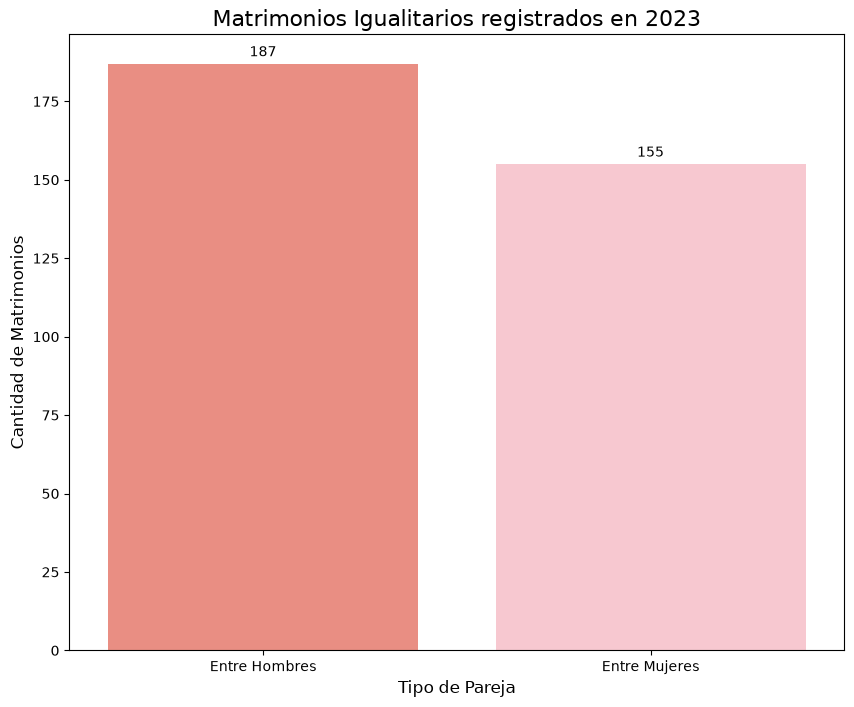


Total Matrimonios Igualitarios: 342
Representan el 0.60% del total de matrimonios en Ecuador.


In [13]:
df['tipo_pareja'] = df.apply(clasificar_pareja,axis=1)
df_mismosex = df[df['tipo_pareja']!='Distinto Sexo']


conteo = df_mismosex['tipo_pareja'].value_counts()

plt.figure(figsize=(10, 8))
ax = sns.barplot(x=conteo.index, y=conteo.values, palette=['salmon','pink'])

plt.title('Matrimonios Igualitarios registrados en 2023', fontsize=16)
plt.xlabel('Tipo de Pareja', fontsize=12)
plt.ylabel('Cantidad de Matrimonios', fontsize=12)
for i in ax.containers:
    ax.bar_label(i, padding=3)

plt.show()

total_mismosex = len(df_mismosex)
total_general = len(df)
porcentaje = (total_mismosex / total_general) * 100
print(f"\nTotal Matrimonios Igualitarios: {total_mismosex}")
print(f"Representan el {porcentaje:.2f}% del total de matrimonios en Ecuador.")


### **¿En qué rango de edad se suelen contraer los matrimonios?**

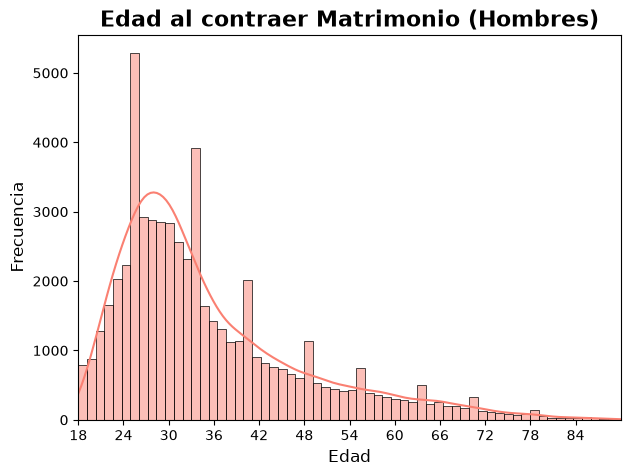

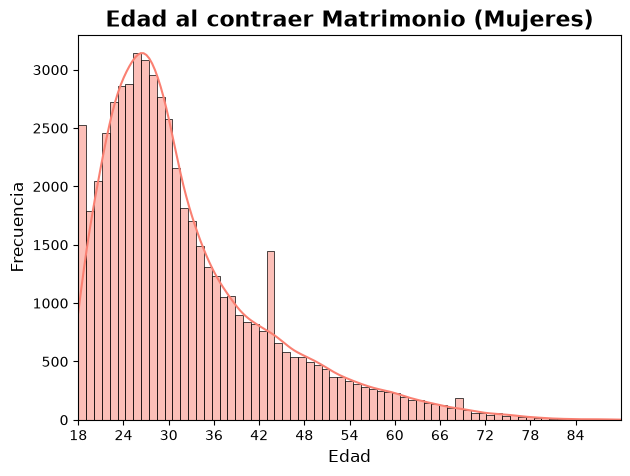

In [14]:


plt.figure(figsize=(7, 5))
hombres_lado1 = df.loc[df['sexo_1'] == 'Hombre', 'edad_1']
hombres_lado2 = df.loc[df['sexo_2'] == 'Hombre', 'edad_2']
edad_hombre = pd.concat([hombres_lado1, hombres_lado2])

sns.histplot(edad_hombre, bins=72, kde=True, color='salmon')
plt.title('Edad al contraer Matrimonio (Hombres)', fontsize=16, fontweight='bold')
plt.xlabel('Edad', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.xlim(left=18)
plt.xlim(right=90)
plt.xticks(np.arange(18, 90, 6))

plt.show()

plt.figure(figsize=(7, 5))
mujer_lado1 = df.loc[df['sexo_1'] == 'Mujer', 'edad_1']
mujer_lado2 = df.loc[df['sexo_2'] == 'Mujer', 'edad_2']
edad_mujer = pd.concat([mujer_lado1, mujer_lado2])

sns.histplot(edad_mujer, bins=72, kde=True, color='salmon')
plt.title('Edad al contraer Matrimonio (Mujeres)', fontsize=16, fontweight='bold')
plt.xlabel('Edad', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.xlim(left=18)
plt.xlim(right=90)
plt.xticks(np.arange(18, 90, 6))

plt.show()


### **¿A qué edad contraen matrimonio en cada región de residencia?**

In [15]:
def obtener_region(val):
    if pd.isna(val): return None
    s = str(val).lower()

    if any(x in s for x in ['guayas', 'el oro', 'esmeralda', 'manab', 'santa elena', 'los r']):
        return 'Costa'

    elif any(x in s for x in ['azuay', 'bolivar', 'bolívar', 'pichincha', 'cañar','santo domingo', 'canar', 'carchi', 'cotopaxi' , 'loja', 'imbabura', 'chimborazo', 'tungurahua']):
        return 'Sierra'

    elif any(x in s for x in ['sucumb', 'napo', 'orellana', 'pastaza', 'morona', 'zamora']):
        return 'Amazonía'

    elif 'gal' in s:
        return 'Insular'

    else:
        return "Exterior"

df['region'] = df['prov_insc'].apply(obtener_region)

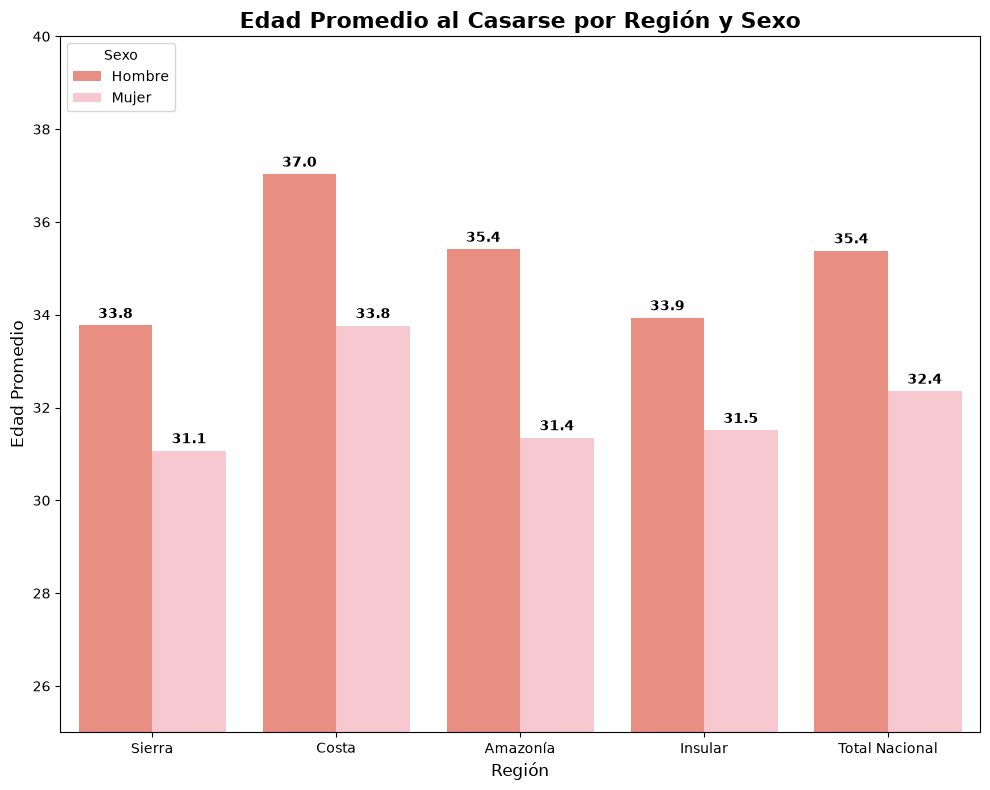

In [16]:
p1 = df[['edad_1', 'sexo_1','region']].rename(columns={'edad_1':'Edad', 'sexo_1':'Sexo'})
p2 = df[['edad_2', 'sexo_2','region']].rename(columns={'edad_2':'Edad', 'sexo_2':'Sexo'})
datos_region = pd.concat([p1, p2]).reset_index(drop=True)

promedios_regionales = datos_region.groupby(['region', 'Sexo'])['Edad'].mean().reset_index()
promedios_nacionales = datos_region.groupby('Sexo')['Edad'].mean().reset_index()
promedios_nacionales['region'] = 'Total Nacional'

tabla_grafico = pd.concat([promedios_regionales, promedios_nacionales], ignore_index=True)

plt.figure(figsize=(10, 8))
orden = ['Sierra','Costa','Amazonía','Insular',"Total Nacional"]
ax = sns.barplot(
    data=tabla_grafico,
    x='region',
    y='Edad',
    hue='Sexo',
    order=orden,
    palette={'Hombre': 'salmon', 'Mujer': 'pink'},
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontweight='bold')

plt.title('Edad Promedio al Casarse por Región y Sexo', fontsize=16, fontweight='bold')
plt.xlabel('Región', fontsize=12)
plt.ylabel('Edad Promedio', fontsize=12)
plt.legend(title='Sexo', loc='upper left')
plt.ylim(25, 40)

plt.tight_layout()
plt.show()

### **¿En qué región se inscriben más matrimonios?**

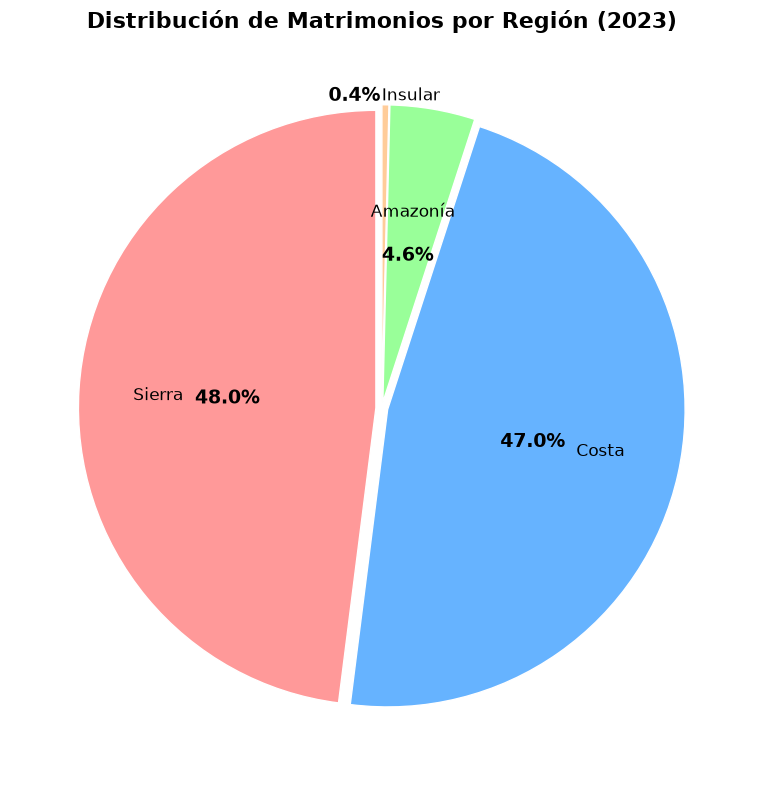

In [17]:
regiones = df['region'].value_counts().copy()

plt.figure(figsize=(8, 8))
colores_personalizados = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0']
explode_values = (0.02, 0.02, 0.02, 0.02)

wedges, texts, autotexts = plt.pie(regiones, labels=regiones.index,
        autopct = '%1.1f%%',
        startangle = 90,           # Empieza rotado para que se vea recto
        pctdistance = 0.5,        # Mueve el % hacia afuera
        colors = colores_personalizados,
        labeldistance=0.65,
        explode = explode_values,
        wedgeprops = {'edgecolor': 'white', 'linewidth': 1})

x, y = texts[2].get_position()
texts[2].set_position((x-0.15, y))

x, y = texts[3].get_position()
texts[3].set_position((0, 1.05))
autotexts[3].set_position((x-0.1, 1.05))

plt.setp(autotexts, size=14, weight="bold", color="black")
plt.setp(texts, size=12, color="black")

plt.title('Distribución de Matrimonios por Región (2023)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## **Sección 3 - Pipeline**

## **Sección 4 - Preguntas de Negocio**

### **¿Existe una diferencia significativa en la brecha de edad entre los contrayentes cuando se trata de un primer matrimonio (ambos solteros) en comparación con las reincidencias (divorciados o viudos)?**


C:\Users\Giancarlo\AppData\Local\Temp\ipykernel_15936\2995476600.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_q1, x='brecha_edad', y='tipo_matrimonio', palette={'Primer Matrimonio': 'salmon', 'Reincidencia': 'pink'}, orient='h')


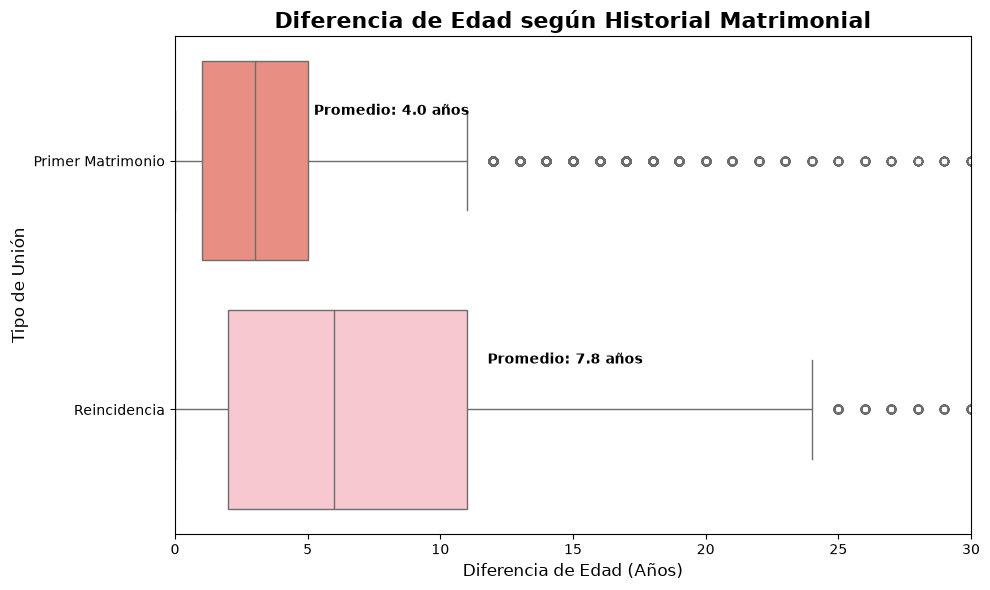

                       mean  50%   max
tipo_matrimonio                       
Primer Matrimonio  4.032585  3.0  68.0
Reincidencia       7.777929  6.0  54.0


In [18]:
df['brecha_edad'] = abs(df['edad_1'] - df['edad_2'])

condicion_primer = (df['est_civi1'] == 'Soltero') & (df['est_civi2'] == 'Soltero')

condicion_reincidencia = (
    (df['est_civi1'].isin(['Divorciado', 'Viudo'])) |
    (df['est_civi2'].isin(['Divorciado', 'Viudo']))
)

df['tipo_matrimonio'] = np.where(condicion_primer, 'Primer Matrimonio',
                        np.where(condicion_reincidencia, 'Reincidencia', 'Otro'))

data_q1 = df[df['tipo_matrimonio'].isin(['Primer Matrimonio', 'Reincidencia'])].copy()

plt.figure(figsize=(10, 6))
sns.boxplot(data=data_q1, x='brecha_edad', y='tipo_matrimonio', palette={'Primer Matrimonio': 'salmon', 'Reincidencia': 'pink'}, orient='h')

plt.title('Diferencia de Edad según Historial Matrimonial', fontsize=16, fontweight='bold')
plt.ylabel('Tipo de Unión', fontsize=12)
plt.xlabel('Diferencia de Edad (Años)', fontsize=12)
plt.xlim(0, 30)

promedios = data_q1.groupby('tipo_matrimonio')['brecha_edad'].mean()
plt.text(x=promedios['Primer Matrimonio'] + 1.2, y=-0.2,
         s=f"Promedio: {promedios['Primer Matrimonio']:.1f} años",
         va='center', color='black', fontweight='bold')

plt.text(x=promedios['Reincidencia'] + 4, y=0.8,
         s=f"Promedio: {promedios['Reincidencia']:.1f} años",
         va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

print(data_q1.groupby('tipo_matrimonio')['brecha_edad'].describe()[['mean', '50%', 'max']])

### **¿Influye el nivel de instrucción de la pareja en la decisión de cuándo casarse?**

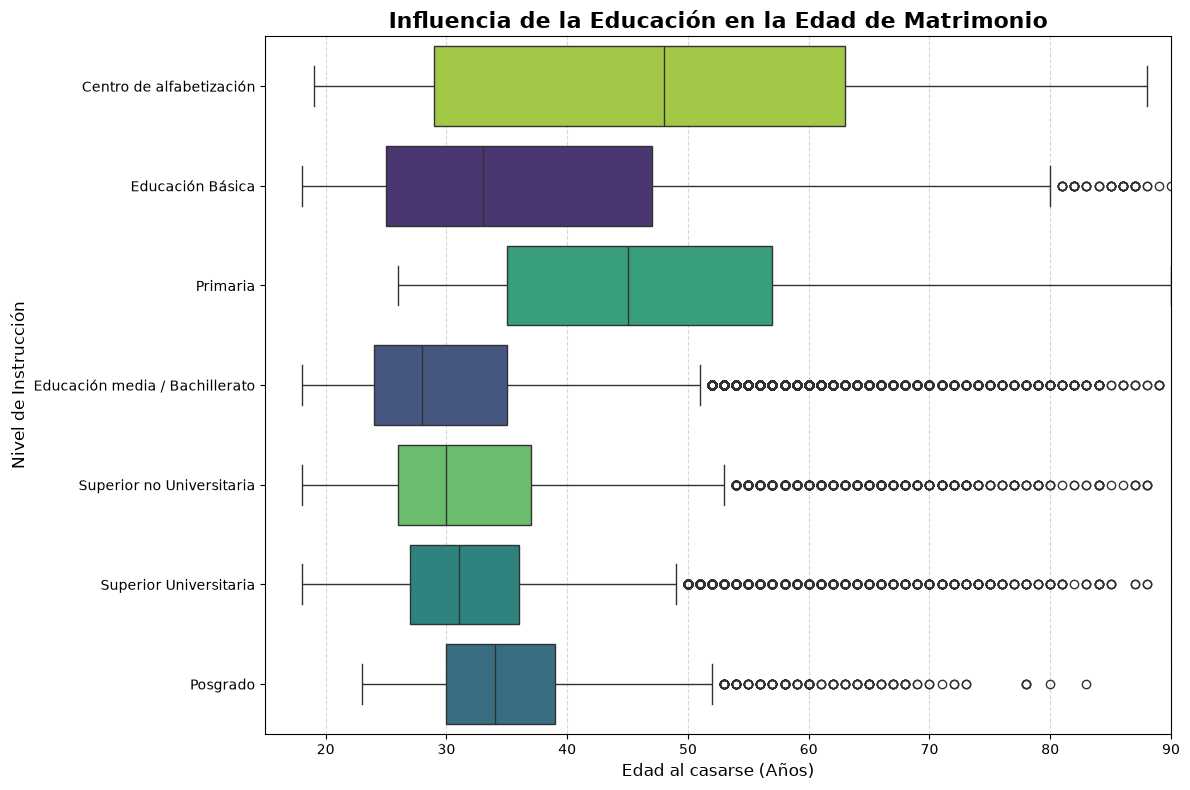

In [19]:
persona1 = df[['niv_inst1', 'edad_1']].rename(columns={'niv_inst1': 'Nivel Educativo', 'edad_1': 'Edad'})
persona2 = df[['niv_inst2', 'edad_2']].rename(columns={'niv_inst2': 'Nivel Educativo', 'edad_2': 'Edad'})
df_personas = pd.concat([persona1, persona2], ignore_index=True)

orden_educacion = [
    'Centro de alfabetización',
    'Educación Básica',
    'Primaria',
    'Educación media / Bachillerato',
    'Superior no Universitaria',
    'Superior Universitaria',
    'Posgrado']
df_plot = df_personas[df_personas['Nivel Educativo'].isin(orden_educacion)]

plt.figure(figsize=(12, 8))

sns.boxplot(data=df_plot, x='Edad', y='Nivel Educativo', hue='Nivel Educativo', order=orden_educacion, palette='viridis',legend=False)

plt.title('Influencia de la Educación en la Edad de Matrimonio', fontsize=16, fontweight='bold')
plt.xlabel('Edad al casarse (Años)', fontsize=12)
plt.ylabel('Nivel de Instrucción', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.xlim(15, 90)
plt.tight_layout()
plt.show()